# Tiền xử lý dữ liệu thời tiết Hà Nội → bài toán phân loại mưa / không mưa

## 0. Kết nối Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import thư viện và cấu hình

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# CẤU HÌNH
DATA_DIR = '/content/drive/MyDrive'
FEATURES = ['temperature', 'humidity', 'pressure', 'wind_speed', 'cloud_cover']

RAIN_THRESHOLD = 0.0      # ngưỡng
PREDICT_TOMORROW = False  # dự đoán hôm nay có mưa
TEST_SIZE = 0.2
SHUFFLE = True            # True: chia ngẫu nhiên (stratify); False: chia theo thời gian (đầu = train, cuối = test)
RANDOM_STATE = 42

TARGET = 'rain_tomorrow' if PREDICT_TOMORROW else 'is_rain'

## 2. Đọc dữ liệu và kiểm tra giá trị thiếu

In [3]:
df = (pd.read_csv(f'{DATA_DIR}/hanoi_weather.csv', parse_dates=['date'])
        .sort_values('date')
        .reset_index(drop=True))

print('Kích thước ban đầu:', df.shape)
print('\nSố giá trị thiếu mỗi cột:\n', df.isna().sum())
df.head()

Kích thước ban đầu: (4018, 7)

Số giá trị thiếu mỗi cột:
 date             0
temperature      0
humidity         0
pressure         0
wind_speed       0
cloud_cover      0
precipitation    0
dtype: int64


,date,temperature,humidity,pressure,wind_speed,cloud_cover,precipitation
0,2015-01-01,16.0,66,1023.4,10.6,1,0.0
1,2015-01-02,15.4,66,1022.8,10.9,14,0.0
2,2015-01-03,15.9,77,1020.1,10.7,68,0.0
3,2015-01-04,18.7,84,1013.5,12.3,83,0.2
4,2015-01-05,20.8,85,1010.7,7.9,75,0.0


## 3. Xử lý giá trị thiếu

In [4]:
df[FEATURES] = df[FEATURES].interpolate(limit_direction='both')
df = df.dropna(subset=['precipitation']).reset_index(drop=True)

## 4. Tạo cột mùa

In [5]:
SEASON_MAP = {11: 'winter', 12: 'winter', 1: 'winter',
              2: 'spring',  3: 'spring',  4: 'spring',
              5: 'summer',  6: 'summer',  7: 'summer',
              8: 'autumn',  9: 'autumn', 10: 'autumn'}

df['season'] = df['date'].dt.month.map(SEASON_MAP)
print(df['season'].value_counts())

season
winter    1012
summer    1012
autumn    1012
spring     982
Name: count, dtype: int64


## 5. Tạo nhãn mục tiêu (nhị phân)

In [6]:
rain_source = df['precipitation'].shift(-1) if PREDICT_TOMORROW else df['precipitation']
df[TARGET] = (rain_source > RAIN_THRESHOLD).astype(int)
if PREDICT_TOMORROW:
    df = df.iloc[:-1]            # dòng cuối không có "ngày mai"

df = df.drop(columns=['precipitation', 'date'])   # tránh data leakage

print('Phân bố nhãn:')
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

Phân bố nhãn:
is_rain
1    2809
0    1209
Name: count, dtype: int64
is_rain
1    0.699
0    0.301
Name: proportion, dtype: float64


## 6. Biểu đồ khám phá dữ liệu (EDA)

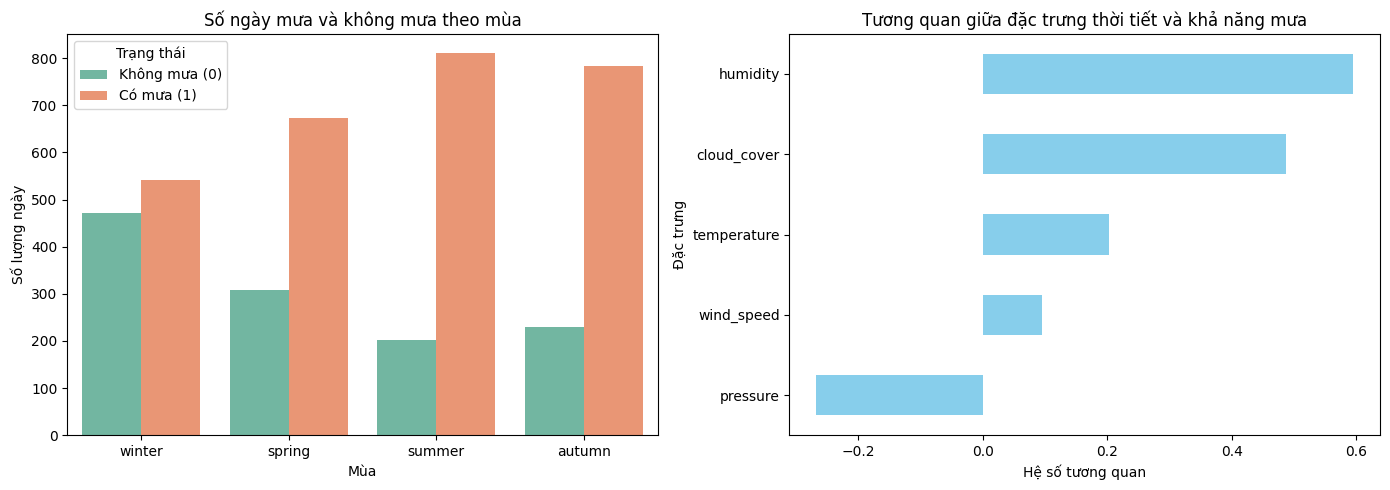

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Số ngày mưa / không mưa theo mùa
sns.countplot(data=df, x='season', hue=TARGET, palette='Set2', ax=axes[0])
axes[0].set_title('Số ngày mưa và không mưa theo mùa')
axes[0].set_xlabel('Mùa')
axes[0].set_ylabel('Số lượng ngày')
axes[0].legend(title='Trạng thái', labels=['Không mưa (0)', 'Có mưa (1)'])

#Tương quan giữa từng đặc trưng và nhãn
corr = df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind='barh', color='skyblue', ax=axes[1])
axes[1].set_title('Tương quan giữa đặc trưng thời tiết và khả năng mưa')
axes[1].set_xlabel('Hệ số tương quan')
axes[1].set_ylabel('Đặc trưng')

plt.tight_layout()
plt.show()

## 7. One-hot cột mùa và chia Train / Test

In [8]:
X = pd.get_dummies(df.drop(columns=TARGET), columns=['season'], dtype=int)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
    shuffle=SHUFFLE, stratify=y if SHUFFLE else None)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Tỉ lệ mưa - train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))
print('Các cột đặc trưng:', list(X.columns))

Train: (3214, 9) | Test: (804, 9)
Tỉ lệ mưa - train: 0.699 | test: 0.699
Các cột đặc trưng: ['temperature', 'humidity', 'pressure', 'wind_speed', 'cloud_cover', 'season_autumn', 'season_spring', 'season_summer', 'season_winter']


## 8. Xử lý outlier (kẹp về ngưỡng IQR)

In [9]:
# Kẹp outlier về ngưỡng IQR (học từ train, áp cho cả train và test)
q1, q3 = X_train[FEATURES].quantile(0.25), X_train[FEATURES].quantile(0.75)
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
X_train[FEATURES] = X_train[FEATURES].clip(low, high, axis=1)
X_test[FEATURES] = X_test[FEATURES].clip(low, high, axis=1)

## 9. Chuẩn hóa đặc trưng (StandardScaler)

In [10]:
scaler = StandardScaler().fit(X_train[FEATURES])      # chỉ học mean/std từ train

X_train, X_test = X_train.copy(), X_test.copy()
X_train[FEATURES] = scaler.transform(X_train[FEATURES])
X_test[FEATURES] = scaler.transform(X_test[FEATURES])  # test dùng mean/std của train

print(X_train[FEATURES].describe().loc[['mean', 'std']].round(3))
X_train.head()

      temperature  humidity  pressure  wind_speed  cloud_cover
mean          0.0      -0.0      -0.0        -0.0          0.0
std           1.0       1.0       1.0         1.0          1.0


,temperature,humidity,pressure,wind_speed,cloud_cover,season_autumn,season_spring,season_summer,season_winter
3317,-1.161489,1.109010,0.782674,-1.159387,0.964810,0,0,0,1
3134,0.733653,1.109010,-1.125282,-1.063733,0.817414,1,0,0,0
981,0.632847,1.109010,-0.475471,-1.374608,0.117288,1,0,0,0
4,-0.697784,0.559582,-0.033046,-1.565915,0.043590,0,0,0,1
955,1.318324,0.010154,-0.890244,0.634118,0.817414,1,0,0,0


## 10. Lưu kết quả vào Google Drive

In [11]:
X_train.assign(**{TARGET: y_train}).to_csv(f'{DATA_DIR}/train_data_weather.csv', index=False)
X_test.assign(**{TARGET: y_test}).to_csv(f'{DATA_DIR}/test_data_weather.csv', index=False)
print('Đã lưu train/test vào', DATA_DIR)

Đã lưu train/test vào /content/drive/MyDrive
